In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [ ]:
seg_path = "/content/drive/MyDrive/KLTN/dataset/data1/left/segmentation_masks/000394.png"
#seg_path = "/content/drive/MyDrive/KLTN/my_sanpo_dataset/segmentation_masks/000003.png"

seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)

print("Seg shape:", seg.shape)
print("Unique labels:", np.unique(seg))


Seg shape: (1242, 2208, 3)
Unique labels: [ 0  1  2  3  4  5  7 12 18 21 22 23 27 28 29]


👉 Segmentation mask của SANPO là ảnh RGB (H, W, 3)

👉 KHÔNG phải label map (H, W)

#### Đọc segmentation cho SANPO

In [ ]:
seg = cv2.imread(seg_path, cv2.IMREAD_COLOR)

seg_id = seg[:,:,2]

#### Segmentation model(ADE20K)

In [ ]:
!pip install transformers

In [ ]:
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
import torch

processor = SegformerImageProcessor.from_pretrained(
    "nvidia/segformer-b5-finetuned-ade-640-640"
)

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b5-finetuned-ade-640-640"
)

model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/image_processing_base.py:370: UserWarning: The following named arguments are not valid for `SegformerImageProcessor.__init__` and were ignored: 'feature_extractor_type', 'reduce_labels'
  image_processor = cls(**image_processor_dict)


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/339M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/339M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

SegformerForSemanticSegmentation(
  (segformer): SegformerModel(
    (encoder): SegformerEncoder(
      (patch_embeddings): ModuleList(
        (0): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
          (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        )
        (1): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (layer_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        )
        (2): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(128, 320, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (layer_norm): LayerNorm((320,), eps=1e-05, elementwise_affine=True)
        )
        (3): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(320, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)

In [ ]:
inputs = processor(images=seg, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits

seg_ade = torch.nn.functional.interpolate(
    logits,
    size=seg.shape[:2],
    mode="bilinear",
    align_corners=False
).argmax(dim=1)[0].cpu().numpy()

In [ ]:
ADE_TO_SANPO = {

# walkable
6:1,     # road
11:3,    # sidewalk
3:17,    # floor -> other walkable
52:15,   # stairs
9:30,    # terrain/grass

# obstacles
4:28,    # tree
12:12,   # pedestrian
20:21,   # car
80:21,   # bus
83:21,   # truck
32:8,    # fence
33:8,    # wall
13:10,   # door
91:24,   # pole
102:23,  # traffic light
103:22,  # traffic sign

# unsafe
29:16    # water
}

In [ ]:
seg_id = np.zeros_like(seg_ade)

for ade_id, sanpo_id in ADE_TO_SANPO.items():
    seg_id[seg_ade == ade_id] = sanpo_id

#### In class_ids

In [ ]:
class_ids = np.unique(seg_id)
print("Class IDs in frame:", class_ids)

Class IDs in frame: [ 0  1  2  3  5  7 12 21 22 23 27 28 29]


#### Hiển thị mask theo CLASS_ID

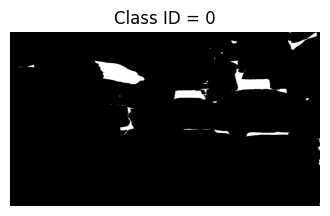

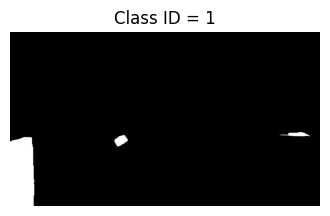

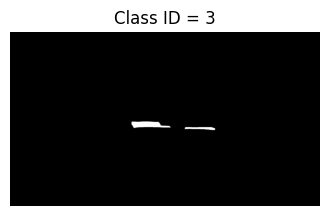

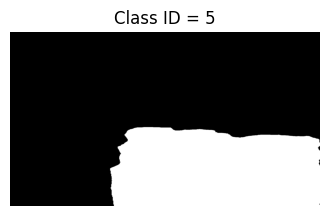

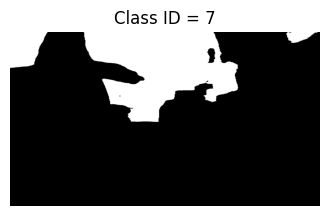

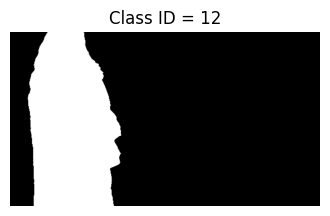

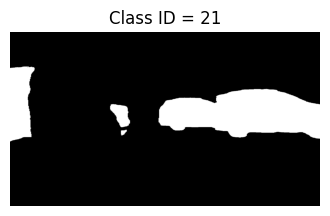

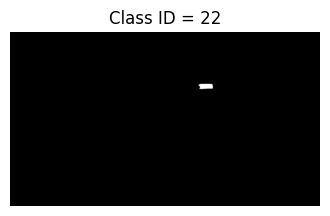

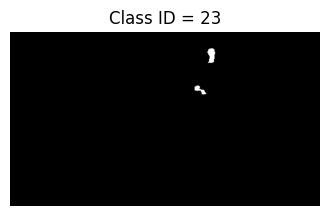

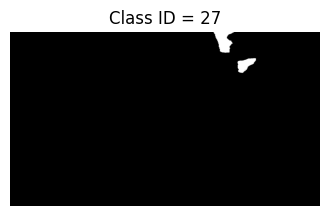

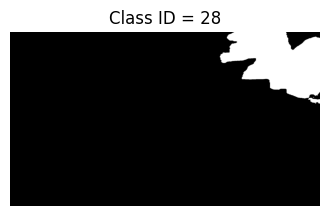

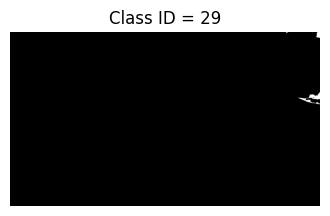

In [ ]:
for cid in class_ids:
    mask = (seg_id == cid)

    if mask.sum() < 500:
        continue

    plt.figure(figsize=(4,3))
    plt.imshow(mask, cmap='gray')
    plt.title(f"Class ID = {cid}")
    plt.axis("off")
    plt.show()

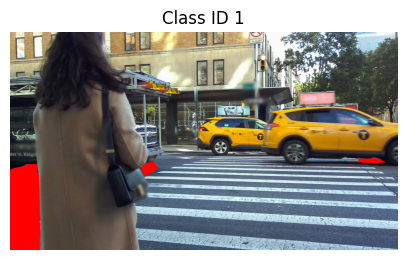

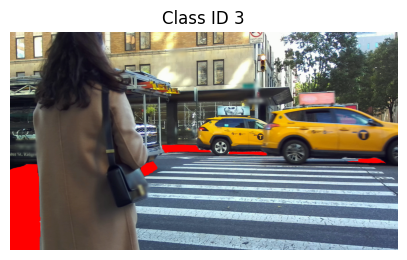

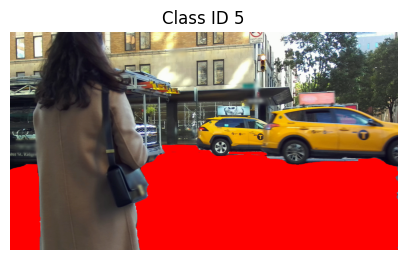

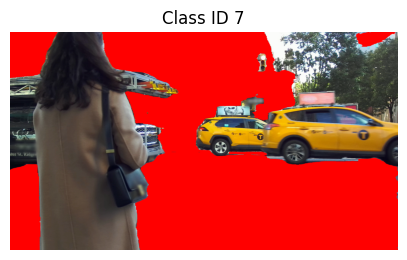

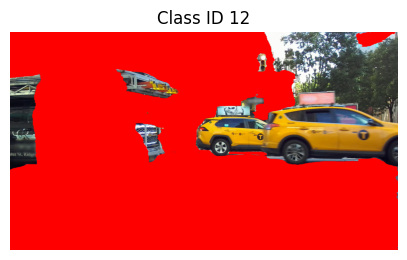

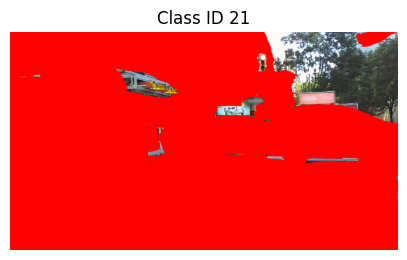

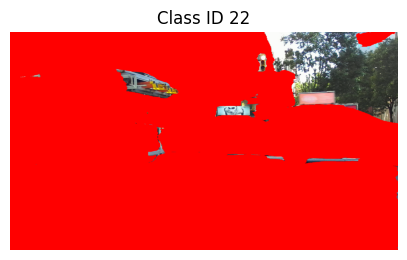

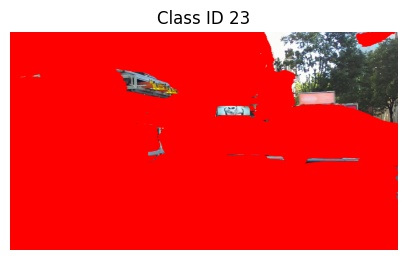

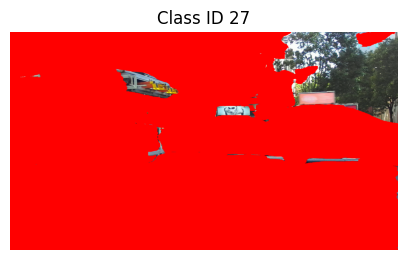

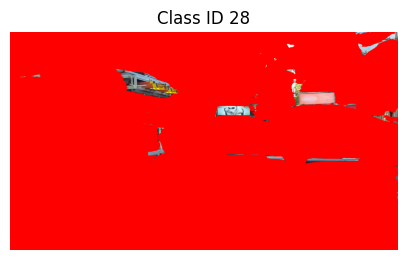

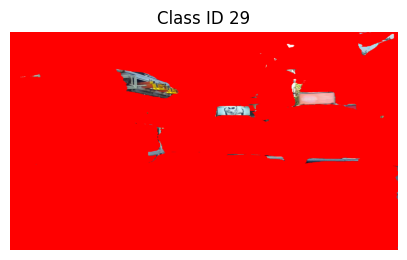

In [ ]:
rgb = cv2.imread("/content/drive/MyDrive/KLTN/dataset/data1/left/video_frames/000394.png")
#rgb = cv2.imread("/content/drive/MyDrive/KLTN/my_sanpo_dataset/segmentation_masks/000003.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

overlay = rgb.copy()

for cid in np.unique(seg_id):
    if cid == 0:
        continue

    mask = (seg_id == cid)
    if mask.sum() < 500:
        continue

    overlay[mask] = [255, 0, 0]

    plt.figure(figsize=(5,4))
    plt.imshow(overlay)
    plt.title(f"Class ID {cid}")
    plt.axis("off")
    plt.show()

#### OVERLAY từng CLASS_ID (ĐỂ HIỂU NGỮ CẢNH)

In [ ]:
SAFE_TO_WALK = {3, 6, 11, 53} #{3, 5, 6, 15, 17, 30}

walkable_mask = np.isin(seg_id, list(SAFE_TO_WALK))

NameError: name 'seg_id' is not defined

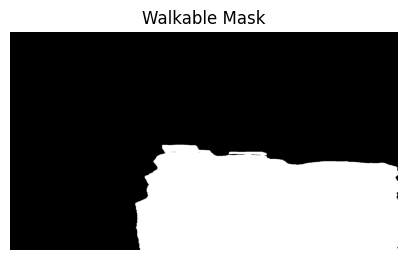

In [ ]:
plt.figure(figsize=(5,4))
plt.imshow(walkable_mask, cmap='gray')
plt.title("Walkable Mask")
plt.axis("off")
plt.show()

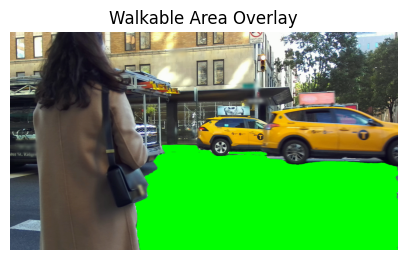

In [ ]:
rgb[walkable_mask] = [0, 255, 0]   # tô xanh vùng đi được

plt.figure(figsize=(5,4))
plt.imshow(rgb)
plt.title("Walkable Area Overlay")
plt.axis("off")
plt.show()

#### LOAD DEPTH & HIỂU KHOẢNG CÁCH

Seg shape: (1024, 576)
RGB shape: (1024, 576, 3)
Actual Depth resolution inferred from data: 1024 576
Depth shape: (1024, 576)
Depth min/max: 0.0 255.0


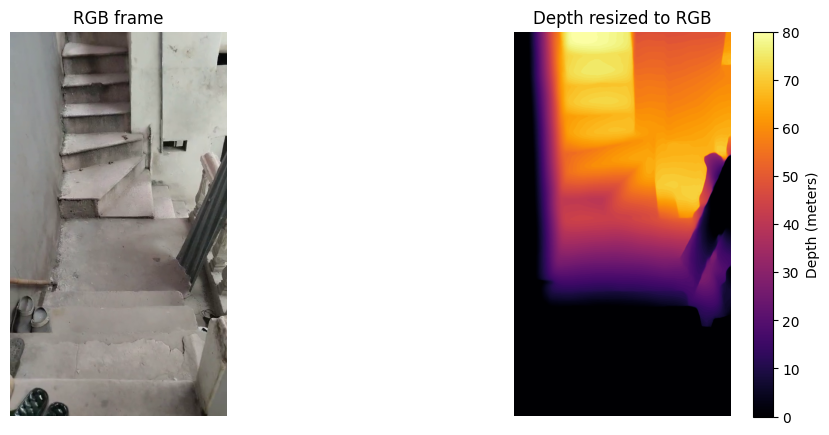

In [ ]:
import cv2
import numpy as np
import gzip
import matplotlib.pyplot as plt

depth_path = "/content/drive/MyDrive/KLTN/my_sanpo_dataset/depth_maps/000002.float16.gz"
seg_path   = "/content/drive/MyDrive/KLTN/my_sanpo_dataset/segmentation_masks/000002.png"
rgb_path   = "/content/drive/MyDrive/KLTN/my_sanpo_dataset/video_frames/000002.png"

# LOAD SEG & RGB (for reference size)
seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)
rgb = cv2.imread(rgb_path)
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

print("Seg shape:", seg.shape)
print("RGB shape:", rgb.shape)

# LOAD DEPTH (.float16.gz)
with gzip.open(depth_path, 'rb') as f:
    depth_bytes = f.read()

raw_depth_data = np.frombuffer(depth_bytes, dtype=np.float16)

H_d = int(raw_depth_data[0])
W_d = int(raw_depth_data[1])

depth = raw_depth_data[2:].reshape((H_d, W_d)).astype(np.float32)

print("Actual Depth resolution inferred from data:", H_d, W_d)
print("Depth shape:", depth.shape)
print("Depth min/max:", depth.min(), depth.max())

# CLIP THEO TÀI LIỆU (0–80m)
depth = np.clip(depth, 0, 80)

# RESIZE DEPTH VỀ KÍCH THƯỚC RGB
depth_resized = cv2.resize(
    depth,
    (rgb.shape[1], rgb.shape[0]), # cv2.resize expects (width, height)
    interpolation=cv2.INTER_NEAREST
)

# SO SÁNH RGB vs DEPTH
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(rgb)
plt.title("RGB frame")
plt.axis("off")

plt.subplot(1,2,2)

plt.imshow(80 - depth_resized, cmap="inferno")
plt.title("Depth resized to RGB")
plt.colorbar(label="Depth (meters)")
plt.axis("off")
plt.subplots_adjust(wspace=0.05)
plt.show()

In [ ]:
H, W = walkable_mask.shape
roi = walkable_mask[int(H*0.5):H, int(W*0.25):int(W*0.75)]

plt.figure(figsize=(4,3))
plt.imshow(roi, cmap="gray")
plt.title("ROI Walkable Mask")
plt.axis("off")
plt.show()

NameError: name 'walkable_mask' is not defined

In [ ]:
walkable_ratio = walkable_mask.sum() / walkable_mask.size
print("Walkable ratio:", walkable_ratio)

Walkable ratio: 0.280309196247287


0.1 – 0.4 → hợp lý

< 0.05 → quá ít (sai class)

**>** 0.6 → quá nhiều (nhầm)

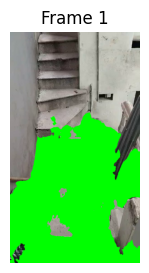

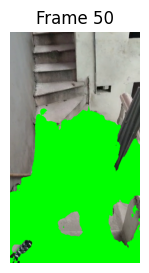

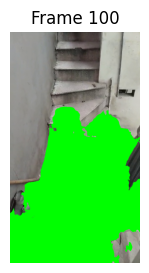

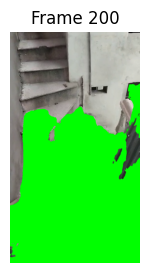

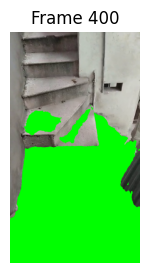

In [ ]:
for idx in [1, 50, 100, 200, 400]:
    seg_path = f"/content/drive/MyDrive/KLTN/my_data/segmentation_masks/{idx:06d}.png"
    rgb_path = f"/content/drive/MyDrive/KLTN/my_data/video_frames/{idx:06d}.png"

    seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)
    rgb = cv2.imread(rgb_path)

    if seg is None:
        print(f"Warning: Could not load segmentation mask for frame {idx} from {seg_path}")
        continue
    if rgb is None:
        print(f"Warning: Could not load RGB image for frame {idx} from {rgb_path}")
        continue

    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    seg_id_current_frame = seg[:,:,2]

    mask = np.isin(seg_id_current_frame, list(SAFE_TO_WALK))

    overlay = rgb.copy()
    overlay[mask] = [0,255,0]

    plt.figure(figsize=(4,3))
    plt.imshow(overlay)
    plt.title(f"Frame {idx}")
    plt.axis("off")
    plt.show()

In [ ]:
seg_path = f"/content/drive/MyDrive/KLTN/dataset/data1/left/segmentation_masks/{idx:06d}.png"
rgb_path = f"/content/drive/MyDrive/KLTN/dataset/data1/left/video_frames/{idx:06d}.png"

seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)
rgb = cv2.imread(rgb_path)
print(seg.shape)
print(rgb.shape)

(1242, 2208, 3)
(1242, 2208, 3)


In [ ]:
import gzip
import numpy as np

depth_path = f"/content/drive/MyDrive/KLTN/my_sanpo_dataset/depth_maps/{idx:06d}.float16.gz"

with gzip.open(depth_path, "rb") as f:
    raw = f.read()

data = np.frombuffer(raw, dtype=np.float16)

# đọc header
h = int(data[0])
w = int(data[1])

# reshape depth
depth = data[2:].reshape(h, w)

print(depth.shape)
print(depth.dtype)
print(depth.min(), depth.max())

(1024, 576)
float16
0.0 255.0


#### Phân tích lối đi hẹp

In [ ]:
H, W = walkable_mask.shape

# Lấy một lát ngang phía trước (vùng người sẽ bước tới)
row = int(H * 0.7)
walkable_row = walkable_mask[row]

# Đếm độ rộng vùng walkable
walkable_width = walkable_row.sum()
relative_width = walkable_width / W

print("Relative walkable width:", relative_width)

Relative walkable width: 0.6612318840579711


- **>** 0.5 → lối đi rộng

- 0.2 – 0.5 → lối đi hẹp

- < 0.2 → nguy hiểm

#### Phân tích lề đường bằng roi phải - trái

In [ ]:
left_roi  = walkable_mask[:, :int(W*0.2)]
center_roi = walkable_mask[:, int(W*0.4):int(W*0.6)]
right_roi = walkable_mask[:, int(W*0.8):]

print("Left walkable ratio:", left_roi.sum() / left_roi.size)
print("Center walkable ratio:", center_roi.sum() / center_roi.size)
print("Right walkable ratio:", right_roi.sum() / right_roi.size)

Left walkable ratio: 0.5586410624367836
Center walkable ratio: 0.7713785460507337
Right walkable ratio: 0.008747385985237648


In [ ]:
import csv
import os
import cv2
import numpy as np

image_dir = "/content/drive/MyDrive/KLTN/my_sanpo_dataset/video_frames"
segmentation_masks_dir = "/content/drive/MyDrive/KLTN/my_sanpo_dataset/segmentation_masks"
csv_output_path = '/content/drive/MyDrive/KLTN/nav_analysis.csv'

# Lấy danh sách file
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.png')])

# Danh sách chứa kết quả
nav_results = []
SAFE_TO_WALK = {3, 5, 6, 15, 17, 30} # Tập ID an toàn theo SANPO

print(f"Bắt đầu phân tích {len(image_files)} frames...")

for frame_id, img_name in enumerate(image_files):
    # Đọc mask của từng frame
    seg_path = os.path.join(segmentation_masks_dir, img_name)
    seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)

    if seg is None:
        continue

    if len(seg.shape) == 3:
        seg_id = seg[:,:,2]
    else:
        seg_id = seg
    walkable_mask = np.isin(seg_id, list(SAFE_TO_WALK)).astype(np.uint8)
    H, W = walkable_mask.shape

    # 1. Tính độ rộng lối đi tại vị trí người dùng sắp bước tới (hàng thứ 70% từ trên xuống)
    row = int(H * 0.7)
    relative_width = walkable_mask[row].sum() / W

    # 2. Phân tích vùng trống để điều hướng (ROI) - Dùng .mean() để ra tỉ lệ 0-1
    left_ratio   = walkable_mask[:, :int(W*0.3)].mean()
    center_ratio = walkable_mask[:, int(W*0.3):int(W*0.7)].mean()
    right_ratio  = walkable_mask[:, int(W*0.7):].mean()

    # 3. Xác định hướng đi tốt nhất (Logic điều hướng)
    if center_ratio > 0.4:
        best_dir = "đi thẳng"
    elif left_ratio > right_ratio:
        best_dir = "rẽ trái"
    else:
        best_dir = "rẽ phải"

    # 4. Lưu vào danh sách
    nav_results.append({
        'frame_id': frame_id,
        'width_ratio': round(relative_width, 2),
        'best_direction': best_dir,
        'is_narrow': 1 if relative_width < 0.3 else 0,
        'safe_left': round(left_ratio, 2),
        'safe_center': round(center_ratio, 2),
        'safe_right': round(right_ratio, 2)
    })

    if frame_id % 100 == 0:
        print(f"Đã xong {frame_id} frames...")

# --- XUẤT FILE CSV ---
with open(csv_output_path, 'w', newline='', encoding='utf-8') as f:
    fieldnames = ['frame_id', 'width_ratio', 'best_direction', 'is_narrow', 'safe_left', 'safe_center', 'safe_right']
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(nav_results)

print(f"XONG! Kết quả đã lưu tại: {csv_output_path}")

Bắt đầu phân tích 211 frames...
Đã xong 0 frames...
Đã xong 100 frames...
Đã xong 200 frames...
XONG! Kết quả đã lưu tại: /content/drive/MyDrive/KLTN/nav_analysis.csv


In [ ]:
import os
import cv2
import numpy as np
import csv

image_dir = "/content/drive/MyDrive/KLTN/dataset/data1/left/video_frames"
seg_dir   = "/content/drive/MyDrive/KLTN/dataset/data1/left/segmentation_masks"
csv_output_path = "/content/drive/MyDrive/KLTN/nav_analysis_my_video.csv"

SAFE_TO_WALK = {3,5,6,15,17,30}

image_files = sorted([f for f in os.listdir(image_dir) if f.endswith(".png")])

nav_results = []

print("Total frames:", len(image_files))

for frame_id, img_name in enumerate(image_files):

    seg_path = os.path.join(seg_dir, img_name)
    seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)

    if seg is None:
        continue

    seg_id = seg[:,:,2]

    walkable_mask = np.isin(seg_id, list(SAFE_TO_WALK)).astype(np.uint8)

    H,W = walkable_mask.shape

    # 1 ROI phía trước người dùng

    roi = walkable_mask[int(H*0.5):H, :]

    left_ratio   = roi[:, :int(W*0.33)].mean()
    center_ratio = roi[:, int(W*0.33):int(W*0.66)].mean()
    right_ratio  = roi[:, int(W*0.66):].mean()

    # 2 Độ rộng lối đi

    row = int(H*0.75)

    walkable_width = walkable_mask[row].sum()

    width_ratio = walkable_width / W

    # 3 Navigation decision

    ratios = {
        "trái": left_ratio,
        "thẳng": center_ratio,
        "phải": right_ratio
    }

    sorted_dirs = sorted(ratios.items(), key=lambda x:x[1], reverse=True)

    best_dir, best_val = sorted_dirs[0]
    second_val = sorted_dirs[1][1]

    confidence = best_val - second_val

    # decision logic

    if best_val < 0.15:
        decision = "cảnh báo nguy hiểm"

    elif confidence < 0.08:
        decision = "không xác định hướng"

    else:

        if best_dir == "trái":
            decision = "rẽ trái"

        elif best_dir == "phải":
            decision = "rẽ phải"

        else:
            decision = "đi thẳng"

    # 4 Narrow path detection

    is_narrow = 1 if width_ratio < 0.25 else 0

    # 5 Save result

    nav_results.append({

        "frame_id": frame_id,

        "safe_left": round(left_ratio,3),
        "safe_center": round(center_ratio,3),
        "safe_right": round(right_ratio,3),

        "width_ratio": round(width_ratio,3),

        "confidence": round(confidence,3),

        "best_direction": decision,

        "is_narrow": is_narrow

    })

    if frame_id % 100 == 0:
        print("Processed:", frame_id)

# SAVE CSV

with open(csv_output_path,"w",newline="",encoding="utf-8") as f:

    fieldnames = [
        "frame_id",
        "safe_left",
        "safe_center",
        "safe_right",
        "width_ratio",
        "confidence",
        "best_direction",
        "is_narrow"
    ]

    writer = csv.DictWriter(f,fieldnames=fieldnames)

    writer.writeheader()
    writer.writerows(nav_results)

print("DONE")
print("CSV saved at:", csv_output_path)

Total frames: 528
Processed: 0
Processed: 100
Processed: 200
Processed: 300
Processed: 400
Processed: 500
DONE
CSV saved at: /content/drive/MyDrive/KLTN/nav_analysis_my_video.csv


#### Overlay YOLO bbox + Walkable Region

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

rgb_path = "/content/drive/MyDrive/KLTN/dataset/data2/left/video_frames/000260.png"
rgb = cv2.imread(rgb_path)
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 42.4 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
results = model(rgb)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

0: 384x640 2 persons, 2 chairs, 334.7ms
Speed: 9.3ms preprocess, 334.7ms inference, 45.8ms postprocess per image at shape (1, 3, 384, 640)


In [ ]:
yolo_detections = []

boxes = results[0].boxes
if boxes is not None:
    for box, cls_id, conf in zip(
        boxes.xyxy.cpu().numpy(),
        boxes.cls.cpu().numpy(),
        boxes.conf.cpu().numpy()
    ):
        x1, y1, x2, y2 = box.astype(int)
        cls_name = model.names[int(cls_id)]

        yolo_detections.append(
            (x1, y1, x2, y2, cls_name, float(conf))
        )

print("Total detections:", len(yolo_detections))

Total detections: 4


In [ ]:
overlay = rgb.copy()

# Tạo mask xanh cho vùng đi được
green_mask = np.zeros_like(rgb)
green_mask[walkable_mask == 1] = [0, 255, 0]

alpha = 0.4
overlay = cv2.addWeighted(overlay, 1.0, green_mask, alpha, 0)

In [ ]:
for x1, y1, x2, y2, cls, conf in yolo_detections:
    if conf < 0.3:
        continue

    cv2.rectangle(
        overlay,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )

    cv2.putText(
        overlay,
        f"{cls} {conf:.2f}",
        (x1, y1 - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1
    )

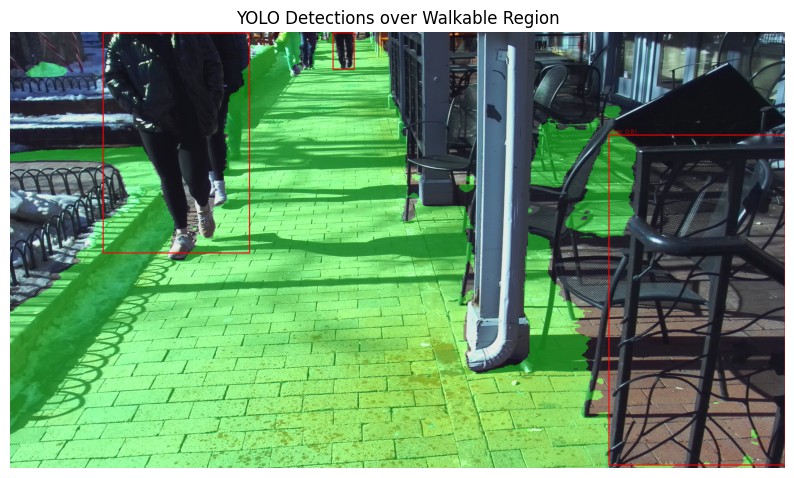

In [ ]:
plt.figure(figsize=(10, 6))
plt.imshow(overlay)
plt.title("YOLO Detections over Walkable Region")
plt.axis("off")
plt.show()

#### Tính toán tỉ lệ chồng lấn (overlap ratio) giữa vùng đi bộ và hộp giới hạn của YOLO

In [ ]:
walkable_yolo_overlaps = []

for x1, y1, x2, y2, cls, conf in yolo_detections:
    if conf < 0.3:
        continue

    # Cắt walkable_mask trong bbox
    bbox_walkable_mask = walkable_mask[y1:y2, x1:x2]

    # Tính số pixel walkable trong bbox
    walkable_pixels = np.sum(bbox_walkable_mask)

    # Tính diện tích bbox
    bbox_area = (x2 - x1) * (y2 - y1)

    overlap_ratio = 0
    if bbox_area > 0:
        overlap_ratio = walkable_pixels / bbox_area

    walkable_yolo_overlaps.append({
        'class': cls,
        'confidence': conf,
        'bbox': (x1, y1, x2, y2),
        'overlap_ratio': overlap_ratio
    })

for item in walkable_yolo_overlaps:
    print(f"Class: {item['class']}, Overlap Ratio: {item['overlap_ratio']:.2f}, Confidence: {item['confidence']:.2f}")

Class: chair, Overlap Ratio: 0.04, Confidence: 0.81
Class: person, Overlap Ratio: 0.21, Confidence: 0.62
Class: person, Overlap Ratio: 0.31, Confidence: 0.59


Overlap rất nhỏ, > 95% bbox Không nằm trong vùng walkable

#### Đặt threshole

In [ ]:
OVERLAP_THRESHOLD = 0.3

filtered_detections = []

for x1, y1, x2, y2, cls, conf in yolo_detections:
    if conf < 0.3:
        continue

    bbox_mask = walkable_mask[y1:y2, x1:x2]

    if bbox_mask.size == 0:
        continue

    overlap_ratio = bbox_mask.sum() / bbox_mask.size

    if overlap_ratio >= OVERLAP_THRESHOLD:
        filtered_detections.append(
            (x1, y1, x2, y2, cls, conf, overlap_ratio)
        )

        print(
            f"[KEEP] {cls}: overlap={overlap_ratio:.2f}, conf={conf:.2f}"
        )
    else:
        print(
            f"[DROP] {cls}: overlap={overlap_ratio:.2f}, conf={conf:.2f}"
        )

[DROP] chair: overlap=0.04, conf=0.81
[DROP] person: overlap=0.21, conf=0.62
[KEEP] person: overlap=0.31, conf=0.59


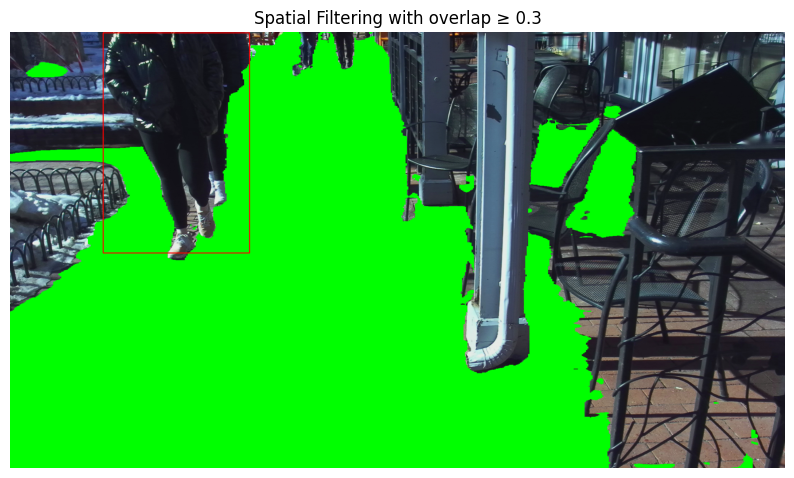

In [ ]:
overlay = rgb.copy()

# vẽ walkable
overlay[walkable_mask] = [0, 255, 0]

# vẽ bbox đã lọc
for x1, y1, x2, y2, cls, conf, overlap in filtered_detections:
    cv2.rectangle(overlay, (x1,y1), (x2,y2), (255,0,0), 2)
    cv2.putText(
        overlay,
        f"{cls} {overlap:.2f}",
        (x1, y1-5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255,0,0),
        1
    )

plt.figure(figsize=(10,6))
plt.imshow(overlay)
plt.title("Spatial Filtering with overlap ≥ 0.3")
plt.axis("off")
plt.show()

Code này chỉ trả lời câu hỏi: "Vật này có nằm trên đường đi hiện tại hay không?"

Nó chưa trả lời: vật có tiến lại gần, có nguy hiểm trong tương lai?

#### Đặt ngưỡng chồng chéo (Overlap threshold)

overlap_ratio ≥ 0.3  →  đối tượng đáng quan tâm

In [ ]:
overlay = rgb.copy()

boxes = results[0].boxes
if boxes is not None:
    for box, cls_id, conf in zip(
        boxes.xyxy.cpu().numpy(),
        boxes.cls.cpu().numpy(),
        boxes.conf.cpu().numpy()
    ):
        x1, y1, x2, y2 = box.astype(int)
        cls_name = model.names[int(cls_id)]

        # Vẽ bbox
        cv2.rectangle(
            overlay,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        label = f"{cls_name} {conf:.2f}"
        text_y = max(y1 - 5, 15)

        # NỀN ĐEN cho chữ
        (tw, th), _ = cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            2
        )
        cv2.rectangle(
            overlay,
            (x1, text_y - th - 4),
            (x1 + tw, text_y),
            (0, 0, 0),
            -1
        )

        # Chữ trắng
        cv2.putText(
            overlay,
            label,
            (x1, text_y - 2),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 255, 255),
            2
        )

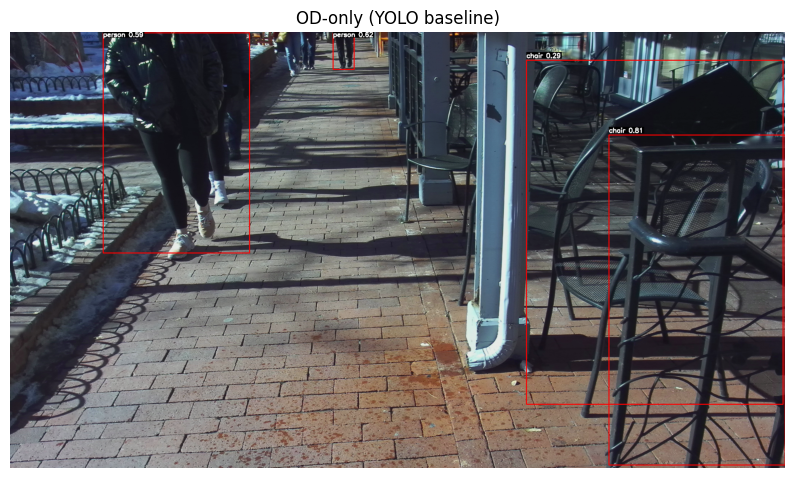

In [ ]:
plt.figure(figsize=(10, 6))
plt.imshow(overlay)
plt.title("OD-only (YOLO baseline)")
plt.axis("off")
plt.show()

Quan sát trên video cho thấy hệ thống chỉ dựa vào phát hiện từng khung hình gặp phải ba vấn đề chính:
- (1) vật thể nhấp nháy do phát hiện không ổn định theo thời gian,
- (2) cảnh báo bật tắt liên tục gây khó chịu cho người dùng
- (3) cảnh báo biến mất trước khi người dùng kịp phản ứng.

Những hiện tượng này cho thấy sự cần thiết của một cơ chế ký ức tạm (temporal memory) thời nhằm duy trì nhận thức môi trường ổn định hơn.

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Định nghĩa các ID lớp an toàn để đi bộ (đã được xác định trước đó)
SAFE_TO_WALK = {3, 5, 6, 15, 17, 30}

# Đường dẫn thư mục đầu vào
base_input_dir = "/content/drive/MyDrive/KLTN/dataset/data2/left"
segmentation_masks_dir = os.path.join(base_input_dir, "segmentation_masks")
video_frames_dir = os.path.join(base_input_dir, "video_frames")

# Đường dẫn thư mục đầu ra
output_dir = "/content/drive/MyDrive/KLTN/walkable_output"

# Tạo thư mục đầu ra nếu chưa tồn tại
os.makedirs(output_dir, exist_ok=True)

# Phạm vi các khung hình để xử lý (ví dụ: từ 0 đến 500, bạn có thể điều chỉnh)
# Bắt đầu từ 1 vì một số file 000000.png có thể không tồn tại hoặc lỗi
start_frame = 1
end_frame = 500 # Ví dụ: xử lý 500 khung hình đầu tiên. Thay đổi nếu cần.

print(f"Bắt đầu xử lý từ khung hình {start_frame} đến {end_frame}...")

for idx in range(start_frame, end_frame + 1):
    seg_path = os.path.join(segmentation_masks_dir, f"{idx:06d}.png")
    rgb_path = os.path.join(video_frames_dir, f"{idx:06d}.png")
    output_frame_path = os.path.join(output_dir, f"walkable_overlay_{idx:06d}.png")

    # Tải ảnh RGB và segmentation mask
    rgb = cv2.imread(rgb_path)
    seg = cv2.imread(seg_path, cv2.IMREAD_UNCHANGED)

    if rgb is None:
        print(f"Cảnh báo: Không thể tải ảnh RGB cho khung hình {idx} từ {rgb_path}")
        continue
    if seg is None:
        print(f"Cảnh báo: Không thể tải segmentation mask cho khung hình {idx} từ {seg_path}")
        continue

    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    # Lấy kênh thứ 3 (kênh xanh lam) của ảnh segmentation để có class ID
    seg_id = seg[:, :, 2]

    # Tạo walkable_mask
    walkable_mask = np.isin(seg_id, list(SAFE_TO_WALK))

    # Tạo ảnh overlay
    overlay = rgb.copy()
    # Tô màu xanh cho vùng có thể đi được
    overlay[walkable_mask] = [0, 255, 0]

    # Lưu ảnh kết quả
    # cv2.imwrite sẽ lưu ảnh dưới định dạng BGR theo mặc định
    # nên cần chuyển lại từ RGB nếu muốn giữ màu sắc nhất quán
    overlay_bgr = cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
    cv2.imwrite(output_frame_path, overlay_bgr)

    if idx % 100 == 0:
        print(f"Đã xử lý {idx} khung hình.")

print(f"Hoàn tất! Các ảnh đã được lưu vào thư mục: {output_dir}")

Bắt đầu xử lý từ khung hình 1 đến 500...
Đã xử lý 100 khung hình.
Đã xử lý 200 khung hình.
Đã xử lý 300 khung hình.
Đã xử lý 400 khung hình.
Cảnh báo: Không thể tải ảnh RGB cho khung hình 465 từ /content/drive/MyDrive/KLTN/dataset/data2/left/video_frames/000465.png
Cảnh báo: Không thể tải ảnh RGB cho khung hình 466 từ /content/drive/MyDrive/KLTN/dataset/data2/left/video_frames/000466.png
Cảnh báo: Không thể tải ảnh RGB cho khung hình 467 từ /content/drive/MyDrive/KLTN/dataset/data2/left/video_frames/000467.png
Cảnh báo: Không thể tải ảnh RGB cho khung hình 468 từ /content/drive/MyDrive/KLTN/dataset/data2/left/video_frames/000468.png
Cảnh báo: Không thể tải ảnh RGB cho khung hình 469 từ /content/drive/MyDrive/KLTN/dataset/data2/left/video_frames/000469.png
Cảnh báo: Không thể tải ảnh RGB cho khung hình 470 từ /content/drive/MyDrive/KLTN/dataset/data2/left/video_frames/000470.png
Cảnh báo: Không thể tải ảnh RGB cho khung hình 471 từ /content/drive/MyDrive/KLTN/dataset/data2/left/video_fr